[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhconning/hunter_eco701/blob/main/notebooks/topic02_earthquake_relief.ipynb)

# Topic 2: The Earthquake Relief Problem
## Multi-Constraint Optimization, Regime Checking, and Shadow Prices

**ECO 701: Microeconomic Theory** | Hunter College, CUNY  
*Instructor: Jonathan Conning*

---

### Overview & Pedagogical Objective

In consumer and producer theory, most introductory textbook models feature a **single constraint** (e.g., a money budget line $p_1 x_1 + p_2 x_2 = I$ or an isocost line). In the real world, however, economic agents routinely face **multiple simultaneous constraints**—such as financial budgets, physical capacities, legal regulations, or carbon limits.

This notebook works through the **Earthquake Relief application** (**Problem Set 1, Question 3**), the core set-piece in the Topic 2 lecture slides ([`slides/02_constrained-optimization/deck.html`](https://jhconning.github.io/hunter_eco701/slides/02_constrained-optimization/deck.html)).

#### The Core Problem:
A disaster relief agency has raised charitable funds to deliver food ($c_F$) and water/tents ($c_W$) by boat to an isolated island:
1. **Preferences:** The relief agency balances survival needs via Cobb-Douglas preferences:
   $$U(c_F, c_W) = c_F \cdot c_W$$
2. **Financial Budget Constraint:** Food costs $p_F = \$1\text{K/ton}$ and water costs $p_W = \$2\text{K/ton}$. Total funds raised equal $I = \$100\text{K}$:
   $$c_F + 2 c_W \le 100$$
3. **Transport Capacity Constraint:** The relief cargo boat has a maximum displacement limit of $T = 80\text{ tons}$, and both commodities weigh 1 ton per ton ($w_F = 1, w_W = 1$):
   $$c_F + c_W \le 80$$

Because the agency faces **two physical and financial fences at once**, we cannot simply assume that both constraints will bind. In this notebook, we follow the exact pedagogical arc from class:
* Map the geometry of the **Feasible Region**
* Form the Lagrangian and analyze the **Three Candidate Regimes**
* Solve each case symbolically by hand (and with **SymPy**)
* Compare candidate bundles and identify the optimal choice
* Solve the problem in one shot using **`scipy.optimize`**
* Test the **Envelope Theorem** and the economic meaning of the shadow prices $\lambda^*$ and $\mu^*$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import sympy as sp
from scipy.optimize import minimize

# Hunter College course color palette
NAVY = "#24325c"
BRICK = "#c0392b"
AMBER = "#b8842a"
SLATE = "#5c6b73"
GREEN = "#2e7d32"
FEASIBLE_FILL = "#edf2f7"
FEASIBLE_EDGE = "#cbd5e1"

# Matplotlib formatting
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Environment initialized successfully.")

Environment initialized successfully.


---

## 1. Parameters and Mathematical Formulation

Let $c_F \ge 0$ denote the tons of food delivered, and $c_W \ge 0$ denote the tons of water/tents delivered.

$$\max_{c_F, c_W} U(c_F, c_W) = c_F \cdot c_W$$

subject to:
$$\text{Budget: } p_F c_F + p_W c_W \le I \implies c_F + 2 c_W \le 100$$
$$\text{Transport: } w_F c_F + w_W c_W \le T \implies c_F + c_W \le 80$$

Let's define these parameter values in Python:

In [2]:
# Base parameters
pF, pW = 1.0, 2.0    # Prices per ton in $K
I_val = 100.0        # Total budget in $K

wF, wW = 1.0, 1.0    # Weight per ton
T_val = 80.0         # Vessel cargo capacity in tons

print(f"Budget line:    cF + {pW/pF:.1f} cW <= {I_val/pF:.1f}  (Slope = {-pW/pF:.1f})")
print(f"Transport line: cF + {wW/wF:.1f} cW <= {T_val/wF:.1f}  (Slope = {-wW/wF:.1f})")

Budget line:    cF + 2.0 cW <= 100.0  (Slope = -2.0)
Transport line: cF + 1.0 cW <= 80.0  (Slope = -1.0)


---

## 2. The Geometry of the Feasible Region

The set of eligible bundles is the **intersection of two half-spaces** (the budget half-space and the cargo half-space) bounded by non-negativity ($c_F \ge 0, c_W \ge 0$).

1. **Budget Line Boundary ($c_F + 2 c_W = 100$):**
   * $c_W$-intercept ($c_F = 0$): $c_W = 100 / 2 = 50\text{ tons}$
   * $c_F$-intercept ($c_W = 0$): $c_F = 100\text{ tons}$
   * Slope: $-\frac{p_W}{p_F} = -2$
2. **Transport Line Boundary ($c_F + c_W = 80$):**
   * $c_W$-intercept ($c_F = 0$): $c_W = 80\text{ tons}$
   * $c_F$-intercept ($c_W = 0$): $c_F = 80\text{ tons}$
   * Slope: $-\frac{w_W}{w_F} = -1$
3. **The Kink Point (Intersection Vertex):**
   Subtracting the transport equation from the budget equation:
   $$(c_F + 2 c_W) - (c_F + c_W) = 100 - 80 \implies c_W = 20$$
   Substituting $c_W = 20$ into $c_F + c_W = 80$:
   $$c_F = 60$$

Thus, the feasible region is a convex polygon with vertices $(0, 0)$, $(50, 0)$, $(20, 60)$, and $(0, 80)$. Let's plot this clearly:

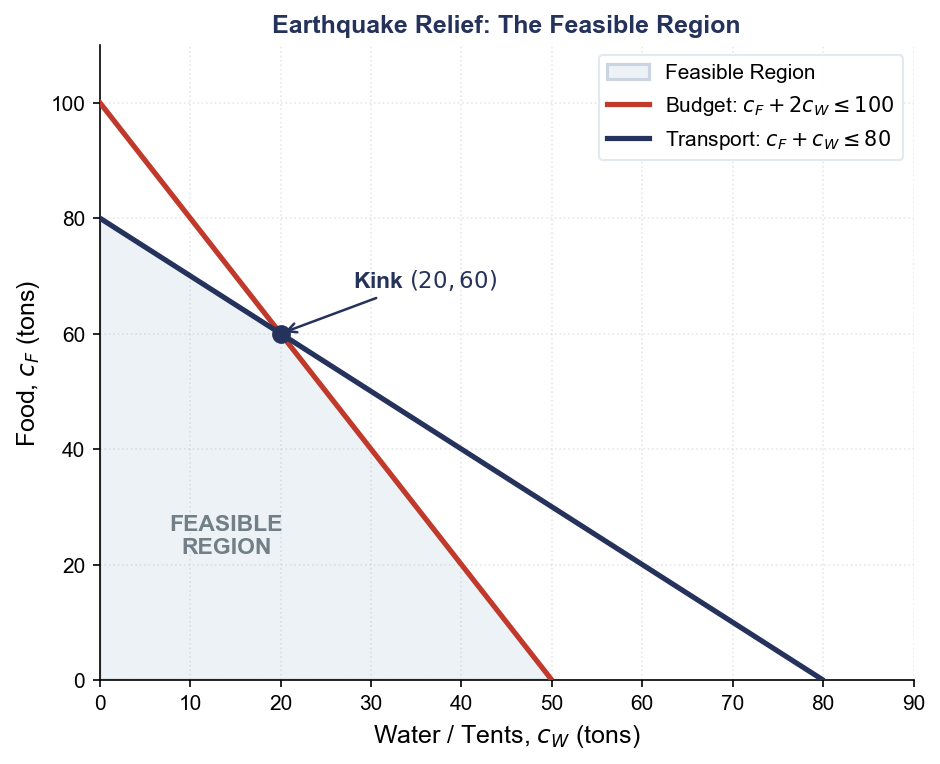

In [3]:
fig, ax = plt.subplots(figsize=(7, 5.5))
cW = np.linspace(0, 90, 400)

# Constraint boundaries
cF_budget = 100.0 - 2.0 * cW
cF_transport = 80.0 - cW

# Shaded feasible polygon
poly_pts = [[0, 0], [50, 0], [20, 60], [0, 80]]
poly = Polygon(poly_pts, closed=True, facecolor=FEASIBLE_FILL, edgecolor=FEASIBLE_EDGE,
               lw=1.5, zorder=1, label="Feasible Region")
ax.add_patch(poly)

# Plot boundary lines
mask_b = (cF_budget >= 0) & (cW <= 52)
ax.plot(cW[mask_b], cF_budget[mask_b], color=BRICK, lw=2.5, zorder=3,
        label=r"Budget: $c_F + 2c_W \leq 100$")

mask_t = (cF_transport >= 0) & (cW <= 82)
ax.plot(cW[mask_t], cF_transport[mask_t], color=NAVY, lw=2.5, zorder=3,
        label=r"Transport: $c_F + c_W \leq 80$")

# Mark intersection vertex
ax.plot(20, 60, "o", color=NAVY, ms=8, zorder=5)
ax.annotate(r"Kink $(20, 60)$", xy=(20, 60), xytext=(28, 68),
            arrowprops=dict(arrowstyle="->", color=NAVY, lw=1.2),
            fontweight="bold", color=NAVY)

# Axis labels and decoration
ax.text(14, 25, "FEASIBLE\nREGION", ha="center", va="center",
        color=SLATE, fontsize=11, fontweight="bold", alpha=0.85)

ax.set_xlim(0, 90)
ax.set_ylim(0, 110)
ax.set_xlabel(r"Water / Tents, $c_W$ (tons)")
ax.set_ylabel(r"Food, $c_F$ (tons)")
ax.grid(True, linestyle=":", alpha=0.3, zorder=0)
ax.legend(loc="upper right", frameon=True, framealpha=0.95, edgecolor="#e2e8f0")
ax.set_title("Earthquake Relief: The Feasible Region", fontsize=12, fontweight="bold", color=NAVY)
plt.show()

---

## 3. The Dual Lagrangian & Complementary Slackness

Because there are two inequality constraints, we assign a separate Lagrange multiplier to each:
* $\lambda \ge 0$: Shadow price of the **money budget** (marginal utility of an extra $\$1\text{K}$ in donations)
* $\mu \ge 0$: Shadow price of **cargo space** (marginal utility of an extra ton of boat capacity)

The Lagrangian is:
$$\mathcal{L}(c_F, c_W, \lambda, \mu) = c_F c_W + \lambda\big(100 - c_F - 2c_W\big) + \mu\big(80 - c_F - c_W\big)$$

### Karush-Kuhn-Tucker (KKT) Complementary Slackness Conditions:
$$\lambda \ge 0, \quad 100 - c_F - 2c_W \ge 0, \quad \lambda\big(100 - c_F - 2c_W\big) = 0$$
$$\mu \ge 0, \quad 80 - c_F - c_W \ge 0, \quad \mu\big(80 - c_F - c_W\big) = 0$$

Each multiplier can either **bind** ($> 0$, constraint holds with equality) or be **slack** ($= 0$, constraint holds with strict inequality).

With $K = 2$ inequality constraints, there are $2^K = 2^2 = 4$ potential regimes:
1. $\lambda = 0, \mu = 0$: Neither binds (unconstrained bliss point). Since utility is strictly increasing, the agency will never voluntarily leave both money and boat space unused.
2. $\lambda = 0, \mu > 0$: **Boat binds, budget is slack.**
3. $\lambda > 0, \mu = 0$: **Budget binds, boat is slack.**
4. $\lambda > 0, \mu > 0$: **Both constraints bind simultaneously (at the kink vertex).**

---

### Economic Intuition: What Determines the Regime?

Which fence the agency hits first depends entirely on the **slope of its indifference curves** (the Marginal Rate of Substitution, $MRS = -\frac{dc_F}{dc_W}$):
* **Steep Indifference Curves (High valuation of water):** The agency hits the budget fence first (slope $-2$).
* **Flat Indifference Curves (High valuation of food):** The agency hits the transport fence first (slope $-1$).
* **Intermediate Indifference Curves ($1 < MRS < 2$):** The agency hits the corner vertex $(20, 60)$ where both fences meet.

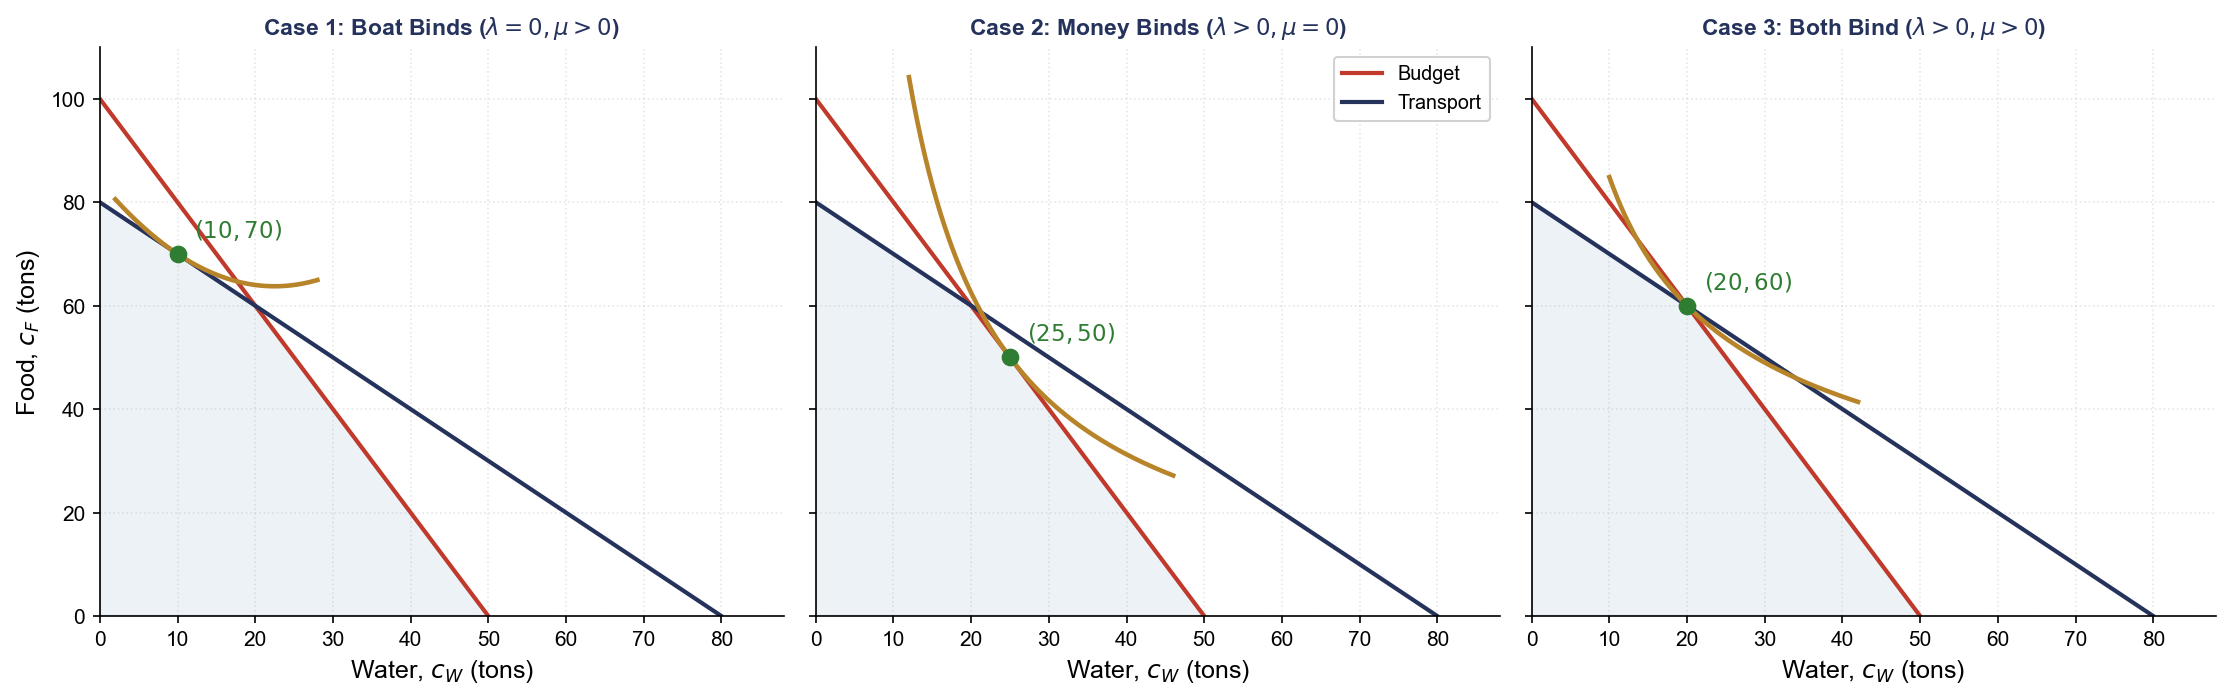

In [4]:
# 3-panel plot illustrating the three qualitative preference regimes
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
cW = np.linspace(0.1, 85, 400)
poly_pts = [[0, 0], [50, 0], [20, 60], [0, 80]]

titles = [
    r"Case 1: Boat Binds ($\lambda=0, \mu>0$)",
    r"Case 2: Money Binds ($\lambda>0, \mu=0$)",
    r"Case 3: Both Bind ($\lambda>0, \mu>0$)"
]

for ax, title in zip(axes, titles):
    ax.add_patch(Polygon(poly_pts, closed=True, facecolor=FEASIBLE_FILL,
                         edgecolor=FEASIBLE_EDGE, lw=1.2, zorder=1))
    ax.plot(cW[100 - 2*cW >= 0], 100 - 2*cW[100 - 2*cW >= 0], color=BRICK, lw=2.0, zorder=2, label="Budget")
    ax.plot(cW[80 - cW >= 0], 80 - cW[80 - cW >= 0], color=NAVY, lw=2.0, zorder=2, label="Transport")
    ax.set_xlim(0, 88)
    ax.set_ylim(0, 110)
    ax.set_xlabel(r"Water, $c_W$ (tons)")
    ax.grid(True, linestyle=":", alpha=0.3, zorder=0)
    ax.set_title(title, fontsize=11, fontweight="bold", color=NAVY)

axes[0].set_ylabel(r"Food, $c_F$ (tons)")

# Case 1 curve (tangent to boat at (10, 70))
cW1 = np.linspace(2, 28, 200)
cF1 = 70 - (cW1 - 10) + 0.04 * (cW1 - 10)**2
axes[0].plot(cW1, cF1, color=AMBER, lw=2.2, zorder=4)
axes[0].plot(10, 70, "o", color=GREEN, ms=7.5, zorder=5)
axes[0].annotate("$(10, 70)$", (10, 70), textcoords="offset points", xytext=(8, 8),
                 fontweight="bold", color=GREEN)

# Case 2 curve (tangent to budget at (25, 50))
cW2 = np.linspace(12, 46, 200)
cF2 = 1250.0 / cW2
axes[1].plot(cW2, cF2, color=AMBER, lw=2.2, zorder=4)
axes[1].plot(25, 50, "o", color=GREEN, ms=7.5, zorder=5)
axes[1].annotate("$(25, 50)$", (25, 50), textcoords="offset points", xytext=(8, 8),
                 fontweight="bold", color=GREEN)

# Case 3 curve (kink at (20, 60))
cW3 = np.linspace(10, 42, 200)
cF3 = (60.0 * np.sqrt(20.0)) / np.sqrt(cW3)
axes[2].plot(cW3, cF3, color=AMBER, lw=2.2, zorder=4)
axes[2].plot(20, 60, "o", color=GREEN, ms=7.5, zorder=5)
axes[2].annotate("$(20, 60)$", (20, 60), textcoords="offset points", xytext=(8, 8),
                 fontweight="bold", color=GREEN)

axes[1].legend(loc="upper right", frameon=True, framealpha=0.9, fontsize=9.5)
fig.tight_layout()
plt.show()

---

## 4. Solving Each Regime Systematically (Hand Solve & SymPy)

To solve an inequality-constrained optimization problem by hand:
1. **Hypothesize a regime** (assume which constraints bind and which are slack).
2. **Solve the resulting equality-constrained problem** via standard FOC tangency or substitution.
3. **Check feasibility:** Test whether the candidate bundle satisfies the slack constraints that were temporarily ignored.
4. **Discard infeasible candidates.**
5. **Compare remaining feasible candidates:** Select the candidate bundle that yields the highest objective value.

Let's test each of the three candidate regimes analytically and with **SymPy**:

### Regime 1: Budget Binds Only ($\lambda > 0, \mu = 0$)
Assume transport capacity is slack ($c_F + c_W < 80$). The problem collapses to standard Cobb-Douglas maximization:
$$MRS = \frac{MU_W}{MU_F} = \frac{c_F}{c_W} = \frac{p_W}{p_F} = 2 \implies c_F = 2 c_W$$
Substitute into the budget constraint $c_F + 2 c_W = 100$:
$$2 c_W + 2 c_W = 100 \implies c_W^* = 25\text{ tons}, \quad c_F^* = 50\text{ tons}$$
* **Feasibility Check:** Total cargo weight $= 50 + 25 = 75\text{ tons} \le 80\text{ tons}$. **FEASIBLE!**
* **Utility:** $U = 50 \times 25 = 1,250$.
* **Shadow Price:** $\lambda^* = c_W^* = 25$ utils per $\$1\text{K}$.

### Regime 2: Transport Binds Only ($\lambda = 0, \mu > 0$)
Assume the money budget is slack ($c_F + 2 c_W < 100$). The agency maximizes subject only to cargo capacity:
$$MRS = \frac{w_W}{w_F} = 1 \implies c_F = c_W$$
Substitute into $c_F + c_W = 80$:
$$c_W = 40\text{ tons}, \quad c_F = 40\text{ tons}$$
* **Feasibility Check:** Total money cost $= 1(40) + 2(40) = 120 > 100$. **INFEASIBLE!**  
  *(The agency runs out of money by $\$20\text{K}$, so this candidate is discarded).*

### Regime 3: Both Constraints Bind ($\lambda > 0, \mu > 0$)
The bundle must sit at the intersection vertex:
$$c_F + 2c_W = 100 \quad \text{and} \quad c_F + c_W = 80 \implies (c_W, c_F) = (20, 60)$$
* **Feasibility Check:** Sits on both boundaries ($c_F + 2c_W = 100$, $c_F + c_W = 80$). **FEASIBLE!**
* **Utility:** $U = 60 \times 20 = 1,200$.

Let's verify this using SymPy:

In [5]:
cF_s, cW_s = sp.symbols('c_F c_W', positive=True)
lam_s, mu_s = sp.symbols('lambda mu', nonnegative=True)

# 1. Regime 1: Budget binds (mu = 0)
eq1_b = sp.Eq(cW_s - lam_s, 0)                  # dL/dcF = cW - lambda = 0
eq2_b = sp.Eq(cF_s - 2*lam_s, 0)                # dL/dcW = cF - 2*lambda = 0
eq3_b = sp.Eq(cF_s + 2*cW_s, 100)               # Budget
sol_regime1 = sp.solve([eq1_b, eq2_b, eq3_b], [cF_s, cW_s, lam_s], dict=True)[0]

# 2. Regime 2: Transport binds (lambda = 0)
eq1_t = sp.Eq(cW_s - mu_s, 0)                   # dL/dcF = cW - mu = 0
eq2_t = sp.Eq(cF_s - mu_s, 0)                   # dL/dcW = cF - mu = 0
eq3_t = sp.Eq(cF_s + cW_s, 80)                  # Transport
sol_regime2 = sp.solve([eq1_t, eq2_t, eq3_t], [cF_s, cW_s, mu_s], dict=True)[0]

# 3. Regime 3: Both bind (vertex)
sol_regime3 = sp.solve([sp.Eq(cF_s + 2*cW_s, 100), sp.Eq(cF_s + cW_s, 80)], [cF_s, cW_s], dict=True)[0]

# Summary Candidate Table
candidates = [
    {
        "Regime": "1. Budget Binds Only",
        "Bundle (cW, cF)": f"({float(sol_regime1[cW_s]):.0f}, {float(sol_regime1[cF_s]):.0f})",
        "Budget Cost": float(sol_regime1[cF_s] + 2*sol_regime1[cW_s]),
        "Cargo Weight": float(sol_regime1[cF_s] + sol_regime1[cW_s]),
        "Feasible?": "Yes (75 <= 80)",
        "Utility U": float(sol_regime1[cF_s] * sol_regime1[cW_s]),
        "Status": "WINNER"
    },
    {
        "Regime": "2. Transport Binds Only",
        "Bundle (cW, cF)": f"({float(sol_regime2[cW_s]):.0f}, {float(sol_regime2[cF_s]):.0f})",
        "Budget Cost": float(sol_regime2[cF_s] + 2*sol_regime2[cW_s]),
        "Cargo Weight": float(sol_regime2[cF_s] + sol_regime2[cW_s]),
        "Feasible?": "No (120 > 100)",
        "Utility U": float(sol_regime2[cF_s] * sol_regime2[cW_s]),
        "Status": "DISCARDED (Violates budget)"
    },
    {
        "Regime": "3. Both Constraints Bind",
        "Bundle (cW, cF)": f"({float(sol_regime3[cW_s]):.0f}, {float(sol_regime3[cF_s]):.0f})",
        "Budget Cost": float(sol_regime3[cF_s] + 2*sol_regime3[cW_s]),
        "Cargo Weight": float(sol_regime3[cF_s] + sol_regime3[cW_s]),
        "Feasible?": "Yes (80 <= 80)",
        "Utility U": float(sol_regime3[cF_s] * sol_regime3[cW_s]),
        "Status": "FEASIBLE SUB-OPTIMAL"
    }
]

print(f"{'Regime':26s} | {'Bundle':10s} | {'Cost ($K)':10s} | {'Weight (t)':10s} | {'Utility U':10s} | {'Result'}")
print("-" * 88)
for c in candidates:
    print(f"{c['Regime']:26s} | {c['Bundle (cW, cF)']:10s} | ${c['Budget Cost']:<9.0f} | {c['Cargo Weight']:<10.0f} | {c['Utility U']:<10.0f} | {c['Status']}")

Regime                     | Bundle     | Cost ($K)  | Weight (t) | Utility U  | Result
----------------------------------------------------------------------------------------
1. Budget Binds Only       | (25, 50)   | $100       | 75         | 1250       | WINNER
2. Transport Binds Only    | (40, 40)   | $120       | 80         | 1600       | DISCARDED (Violates budget)
3. Both Constraints Bind   | (20, 60)   | $100       | 80         | 1200       | FEASIBLE SUB-OPTIMAL


---

## 5. Choosing the Winner & Solution Map

Comparing the two feasible candidates:
$$U(\text{Regime 1}) = 1,250 > 1,200 = U(\text{Regime 3})$$

* **The Constrained Optimum:**
  $$(c_W^*, c_F^*) = (25, 50), \quad U^* = 1,250$$
* **Resource Utilization:**
  * Money: $50 + 2(25) = \$100\text{K}$ (Budget is **100% exhausted**).
  * Boat Capacity: $50 + 25 = 75\text{ tons}$ out of $80\text{ tons}$ capacity (**5 tons of boat capacity are left empty!**).

Let's plot the complete indifference curve map showing all candidate points and the 5-ton slack capacity:

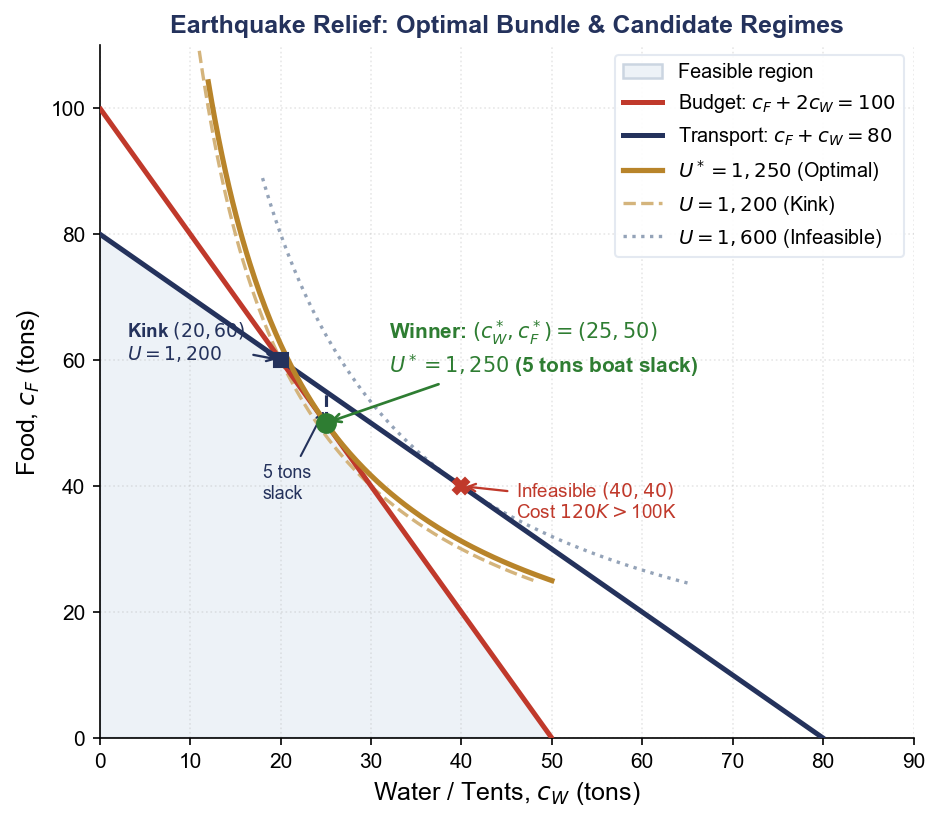

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
cW = np.linspace(0.1, 85, 400)

# Feasible polygon
poly_pts = [[0, 0], [50, 0], [20, 60], [0, 80]]
ax.add_patch(Polygon(poly_pts, closed=True, facecolor=FEASIBLE_FILL,
                     edgecolor=FEASIBLE_EDGE, lw=1.2, zorder=1, label="Feasible region"))

# Constraint lines
ax.plot(cW[100 - 2*cW >= 0], 100 - 2*cW[100 - 2*cW >= 0], color=BRICK, lw=2.4, zorder=3,
        label=r"Budget: $c_F + 2c_W = 100$")
ax.plot(cW[80 - cW >= 0], 80 - cW[80 - cW >= 0], color=NAVY, lw=2.4, zorder=3,
        label=r"Transport: $c_F + c_W = 80$")

# Indifference curves
# U* = 1250 (Optimal, tangent at (25, 50))
cW_opt = np.linspace(12, 50, 200)
ax.plot(cW_opt, 1250.0 / cW_opt, color=AMBER, lw=2.5, zorder=4, label=r"$U^* = 1,250$ (Optimal)")

# U = 1200 (Through kink (20, 60))
cW_kink = np.linspace(11, 48, 200)
ax.plot(cW_kink, 1200.0 / cW_kink, color="#d4b47c", lw=1.6, linestyle="--", zorder=2,
        label=r"$U = 1,200$ (Kink)")

# U = 1600 (Through (40, 40), infeasible)
cW_inf = np.linspace(18, 65, 200)
ax.plot(cW_inf, 1600.0 / cW_inf, color="#94a3b8", lw=1.6, linestyle=":", zorder=2,
        label=r"$U = 1,600$ (Infeasible)")

# Candidate markers
# 1. Optimal (25, 50)
ax.plot(25, 50, "o", color=GREEN, ms=9, zorder=6)
ax.annotate(r"Winner: $(c_W^*, c_F^*) = (25, 50)$" + "\n" + r"$U^* = 1,250$ (5 tons boat slack)",
            xy=(25, 50), xytext=(32, 58),
            arrowprops=dict(arrowstyle="->", color=GREEN, lw=1.3),
            fontweight="bold", color=GREEN, fontsize=10)

# 2. Kink (20, 60)
ax.plot(20, 60, "s", color=NAVY, ms=7, zorder=5)
ax.annotate("Kink $(20, 60)$\n$U = 1,200$", xy=(20, 60), xytext=(3, 60),
            arrowprops=dict(arrowstyle="->", color=NAVY, lw=1.1),
            color=NAVY, fontsize=9, fontweight="bold")

# 3. Infeasible (40, 40)
ax.plot(40, 40, "X", color=BRICK, ms=8, zorder=5)
ax.annotate("Infeasible $(40, 40)$\nCost $120K > $100K", xy=(40, 40), xytext=(46, 35),
            arrowprops=dict(arrowstyle="->", color=BRICK, lw=1.1),
            color=BRICK, fontsize=9)

# Slack boat capacity indicator at cW = 25
ax.vlines(25, 50, 55, color=NAVY, linestyle="--", lw=1.5, zorder=3)
ax.annotate("5 tons\nslack", xy=(25, 52.5), xytext=(18, 38),
            arrowprops=dict(arrowstyle="->", color=NAVY, lw=1.0),
            color=NAVY, fontsize=8.5)

ax.set_xlim(0, 90)
ax.set_ylim(0, 110)
ax.set_xlabel(r"Water / Tents, $c_W$ (tons)")
ax.set_ylabel(r"Food, $c_F$ (tons)")
ax.grid(True, linestyle=":", alpha=0.3, zorder=0)
ax.legend(loc="upper right", frameon=True, framealpha=0.92, edgecolor="#e2e8f0", fontsize=9.5)
ax.set_title("Earthquake Relief: Optimal Bundle & Candidate Regimes",
             fontsize=12, fontweight="bold", color=NAVY)
plt.show()

---

## 6. Solving It with Python (`scipy.optimize`)

Checking regimes by hand works well for 2 constraints ($2^2 = 4$ cases). But with $K$ inequality constraints, there are $2^K$ combinatorial regimes:
* $K = 5 \implies 32$ regimes
* $K = 10 \implies 1,024$ regimes
* $K = 20 \implies 1,048,576$ regimes!

In computational economics and applied policy analysis, we hand the objective and all constraints directly to an algorithmic solver such as Sequential Least Squares Quadratic Programming (**SLSQP**).

`scipy.optimize.minimize` handles inequalities in the standard format `fun(c) >= 0`:

In [7]:
# 1. Objective: Scipy minimizes, so we minimize negative utility
def objective(c):
    return -(c[0] * c[1])

# 2. Inequality constraints: fun(c) >= 0
constraints = [
    {"type": "ineq", "fun": lambda c: 100.0 - (c[0] + 2.0 * c[1])}, # Budget: 100 - cF - 2cW >= 0
    {"type": "ineq", "fun": lambda c: 80.0  - (c[0] + c[1])}        # Cargo:  80 - cF - cW  >= 0
]

# 3. Non-negativity bounds: cF >= 0, cW >= 0
bounds = [(0, None), (0, None)]

# 4. Solve using SLSQP
result = minimize(objective, x0=[10.0, 10.0], constraints=constraints,
                  bounds=bounds, method="SLSQP")

cF_opt, cW_opt = result.x
U_opt = -result.fun

print(f"SciPy SLSQP Solution:")
print(f"  Food  (cF*) = {cF_opt:.4f} tons")
print(f"  Water (cW*) = {cW_opt:.4f} tons")
print(f"  Max Utility = {U_opt:.4f}")
print(f"  Success:    = {result.success} ({result.message})")

SciPy SLSQP Solution:
  Food  (cF*) = 50.0000 tons
  Water (cW*) = 25.0000 tons
  Max Utility = 1250.0000
  Success:    = True (Optimization terminated successfully)


---

## 7. Economic Interpretation of Shadow Prices (The Envelope Theorem)

The Lagrange multipliers $\lambda^*$ and $\mu^*$ are **shadow prices** measuring the marginal value of relaxing each constraint. By the **Envelope Theorem**:
$$\lambda^* = \frac{\partial V}{\partial I}, \qquad \mu^* = \frac{\partial V}{\partial T}$$
where $V(I, T) = \max U(c_F, c_W)$ is the indirect utility function.

### Analytical Shadow Price of Budget ($\lambda^*$):
When the budget binds, $c_F(I) = \frac{I}{2 p_F} = \frac{I}{2}$ and $c_W(I) = \frac{I}{2 p_W} = \frac{I}{4}$.
$$V(I) = c_F(I) \cdot c_W(I) = \left(\frac{I}{2}\right)\left(\frac{I}{4}\right) = \frac{I^2}{8}$$
Differentiating with respect to $I$:
$$\lambda^* = \frac{d V}{d I} = \frac{2I}{8} = \frac{I}{4}$$
At $I = \$100\text{K}$:
$$\lambda^* = \frac{100}{4} = 25\text{ utils per } \$1\text{K}$$

### Numerical Perturbation Test:
Let's verify this numerically by re-solving the problem with $I = 101$ and with $T = 81$:

In [8]:
def solve_relief(I_local, T_local):
    cons = [
        {"type": "ineq", "fun": lambda c: I_local - (c[0] + 2.0 * c[1])},
        {"type": "ineq", "fun": lambda c: T_local - (c[0] + c[1])}
    ]
    res = minimize(lambda c: -(c[0]*c[1]), x0=[10.0, 10.0],
                   constraints=cons, bounds=[(0, None), (0, None)], method="SLSQP")
    return -res.fun, res.x[0], res.x[1]

# Baseline at I = 100, T = 80
U_base, cF_base, cW_base = solve_relief(100.0, 80.0)

# 1. Perturb Budget by $1K (I: 100 -> 101)
U_plus_I, cF_plus_I, cW_plus_I = solve_relief(101.0, 80.0)
delta_U_budget = U_plus_I - U_base
lambda_theory = 100.0 / 4.0

print("1. BUDGET PERTURBATION (I: 100 -> 101):")
print(f"   U*(I=100) = {U_base:.4f}")
print(f"   U*(I=101) = {U_plus_I:.4f}")
print(f"   Numerical dU/dI     = {delta_U_budget:.4f} utils/$1K")
print(f"   Theoretical lambda* = {lambda_theory:.4f} utils/$1K")
print(f"   -> Match confirmed! Relaxing budget raises welfare by ~lambda*.")

# 2. Perturb Transport Capacity by 1 ton (T: 80 -> 81)
U_plus_T, cF_plus_T, cW_plus_T = solve_relief(100.0, 81.0)
delta_U_cargo = U_plus_T - U_base

print("\n2. TRANSPORT PERTURBATION (T: 80 -> 81):")
print(f"   U*(T=80) = {U_base:.4f}")
print(f"   U*(T=81) = {U_plus_T:.4f}")
print(f"   Numerical dU/dT     = {delta_U_cargo:.6f} utils/ton")
print(f"   Theoretical mu*     = 0.000000 utils/ton")
print(f"   -> Match confirmed! Transport is slack, so expanding boat capacity adds 0 value.")

1. BUDGET PERTURBATION (I: 100 -> 101):
   U*(I=100) = 1250.0000
   U*(I=101) = 1275.1250
   Numerical dU/dI     = 25.1250 utils/$1K
   Theoretical lambda* = 25.0000 utils/$1K
   -> Match confirmed! Relaxing budget raises welfare by ~lambda*.

2. TRANSPORT PERTURBATION (T: 80 -> 81):
   U*(T=80) = 1250.0000
   U*(T=81) = 1250.0000
   Numerical dU/dT     = 0.000000 utils/ton
   Theoretical mu*     = 0.000000 utils/ton
   -> Match confirmed! Transport is slack, so expanding boat capacity adds 0 value.


### Economic Interpretation of the Perturbation Results

The numerical perturbation experiments directly demonstrate the economic meaning of the **Envelope Theorem** and **shadow prices**:

1. **Why $\Delta U^* / \Delta I \approx 25.125 \approx \lambda^* = 25$:**
   An extra $\$1\text{K}$ in donations yields approximately $25$ additional utils of satisfaction. Because the financial budget constraint is actively binding, the relief organization immediately converts that additional funding into $0.5$ tons of food and $0.25$ tons of water ($c_F = I/2, c_W = I/4$), directly relaxing the binding constraint. The slight discrepancy between the discrete change ($25.125$) and the theoretical derivative ($\lambda^* = 25$) is due to the second-order curvature of indirect utility: $V(I) = I^2/8$, so $\Delta V = \frac{101^2 - 100^2}{8} = \frac{201}{8} = 25.125$. The theoretical shadow price $\lambda^* = \frac{\partial V}{\partial I} = 25$ is the exact instantaneous derivative.

2. **Why $\Delta U^* / \Delta T = 0 = \mu^*$:**
   An extra ton of vessel cargo capacity yields **zero additional welfare** ($\mu^* = 0$). Why? Because at the constrained optimum $(c_W^*, c_F^*) = (25, 50)$, the agency ships $75$ tons of cargo on an $80$-ton boat, leaving **$5$ tons of cargo space empty**. Providing an $81$-ton vessel instead of an $80$-ton vessel changes nothing—the agency does not have the money to buy more supplies to fill that empty space. Money, not transport capacity, is the active bottleneck.

3. **Policy Relevance for Aid Programs:**
   If a donor offers to donate extra shipping space or charter a larger vessel, the agency gains zero value from the gift unless accompanied by cash to purchase goods. Aid is most impactful when directed at the **actively binding bottleneck**.

---

## 8. Key Takeaways for Microeconomic Theory

1. **Complementary Slackness:**
   A constraint only commands a positive economic shadow price ($\lambda > 0$ or $\mu > 0$) if it is **actively binding**. Slack constraints have zero marginal value ($\mu = 0$) because you already have room to spare.
2. **Why We Teach Hand Solving:**
   Evaluating candidate regimes by hand trains you to diagnose the **economic bottleneck** of a system—identifying which resource is genuinely scarce.
3. **Why We Use Numerical Solvers:**
   For real-world problems with dozens of constraints ($2^K$ combinatorial explosion), numerical algorithms like SLSQP locate the active constraint regime automatically in milliseconds.
4. **Policy Relevance:**
   In humanitarian aid and public policy, well-meaning interventions often subsidize physical infrastructure or transport. Understanding shadow prices ensures that resources are directed where they actively relieve binding bottlenecks rather than accumulating unused slack.